# 1. Saúde da Mulher na África Subsaariana

Contracepção, pré-natal e desigualdades sociais: Quanto das diferenças rurais e urbanas se relaciona à riqueza e à escolaridade?

# 2. Equipe

Henrique Lima Gusmão (2025014508); 
Felipe Pires Franco ();
Izabella Galdino Correia ();
Alice Lina Oliveira da Silva ().

# 3. Descrição dos dados

### 3.1 Obtenção dos dados

1. Acessamos o [DHS Program](https://dhsprogram.com/data/Access-Instructions.cfm), solicitamos acesso e, após a autorização pela agência, baixamos os dados diretamente no site em arquivos ZIP.
2. Extraímos os arquivos Stata (.dta) e selecionamos as entrevistas de mulheres. As entrevistas masculinas e de casais ficaram fora do banco estudado; domicílios, moradores e crianças foram mantidos como contexto familiar.
3. Executamos os scripts de preparação, selecionamos as variáveis relevantes e convertemos os arquivos em CSV compactado, utilizado para popular o banco SQLite.
4. Utilizamos a aplicação **Python/Flask** do projeto, com label_maps.py, para relacionar os códigos das colunas e das respostas aos seus significados em português e conferir os dados.

**Todos esses dados brutos + Python/Flask com o banco de dados populado está disponível no [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData). O acesse para verificar as informações aqui constadas :)**


**Esquema relacional e carga executável**

O DDL define as dez relações normalizadas. A carga lê somente IR, HR, PR, BR e KR, seleciona as colunas abaixo e mantém ausências como NULL. MR e CR são descartados; moradores e crianças permanecem como contexto familiar.

Os CSVs reproduzem a base principal. Pesquisas suplementares podem ser informadas no argumento suplementos; o banco atual já as contém. Um banco populado com o mesmo esquema é reutilizado após PRAGMA foreign_key_check. Bancos ausentes ou vazios disparam a carga; vínculos inválidos interrompem a execução.

Como os CSVs têm colunas variáveis por país, docs/esquemas_csv.csv conserva a descrição da preparação recuperada do histórico. Se existir dados/relevantes/manifesto_selecao.csv, ele tem prioridade. A leitura confere cabeçalhos, metadados e contagens antes de inserir os valores.


In [ ]:
from pathlib import Path
from contextlib import closing
import sqlite3
import pandas as pd
from IPython.display import display

DDL = """
CREATE TABLE Pais(codigo TEXT PRIMARY KEY, nome TEXT NOT NULL UNIQUE);
CREATE TABLE Levantamento(id TEXT PRIMARY KEY, pais_codigo TEXT NOT NULL REFERENCES Pais(codigo), fase TEXT NOT NULL, UNIQUE(pais_codigo,fase));
CREATE TABLE Domicilio(
  id TEXT PRIMARY KEY, levantamento_id TEXT NOT NULL REFERENCES Levantamento(id),
  cluster INTEGER NOT NULL, numero INTEGER NOT NULL, regiao INTEGER,
  residencia INTEGER CHECK(residencia IN(1,2)), riqueza INTEGER CHECK(riqueza BETWEEN 1 AND 5),
  eletricidade INTEGER CHECK(eletricidade IN(0,1)), fonte_agua INTEGER, membros INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('HR','IR_sem_HR','IR_completo')),
  UNIQUE(levantamento_id,cluster,numero));
CREATE TABLE Mulher(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  idade INTEGER, escolaridade INTEGER CHECK(escolaridade BETWEEN 0 AND 3),
  filhos_nascidos_vivos INTEGER, idade_primeiro_nascimento INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Entrevista(
  mulher_id TEXT PRIMARY KEY REFERENCES Mulher(id), ano INTEGER, mes INTEGER,
  data_cmc INTEGER, peso REAL CHECK(peso>0), usa_metodo INTEGER CHECK(usa_metodo IN(0,1)),
  coorte TEXT NOT NULL CHECK(coorte IN('nucleo_e_contracepcao','nucleo_exclusivo','contracepcao')));
CREATE TABLE Nascimento(
  id TEXT PRIMARY KEY, mulher_id TEXT NOT NULL REFERENCES Mulher(id), indice INTEGER NOT NULL CHECK(indice>=1),
  ano INTEGER, mes INTEGER, data_cmc INTEGER, sexo INTEGER CHECK(sexo IN(1,2)), vivo INTEGER CHECK(vivo IN(0,1)),
  consultas_prenatal_codigo INTEGER, local_parto_codigo INTEGER, cesarea_codigo INTEGER,
  assistencia_medico_codigo INTEGER, assistencia_m3b_codigo INTEGER,
  origem TEXT NOT NULL CHECK(origem IN('BR','KR_sem_BR')), UNIQUE(mulher_id,indice));
CREATE TABLE Crianca(
  nascimento_id TEXT PRIMARY KEY REFERENCES Nascimento(id), idade_anos INTEGER,
  diarreia_codigo INTEGER, cartao_vacina_codigo INTEGER);
CREATE TABLE Morador(
  id TEXT PRIMARY KEY, domicilio_id TEXT NOT NULL REFERENCES Domicilio(id), linha INTEGER NOT NULL,
  sexo INTEGER, idade INTEGER, escolaridade_codigo INTEGER, relacao_chefe_codigo INTEGER,
  UNIQUE(domicilio_id,linha));
CREATE TABLE Metodo(
  id INTEGER PRIMARY KEY, nome TEXT NOT NULL UNIQUE, classe TEXT NOT NULL CHECK(classe IN('Moderno','Tradicional')));
CREATE TABLE Conhecimento_Metodo(
  mulher_id TEXT NOT NULL REFERENCES Mulher(id), metodo_id INTEGER NOT NULL REFERENCES Metodo(id),
  nivel INTEGER NOT NULL CHECK(nivel BETWEEN 0 AND 7), PRIMARY KEY(mulher_id,metodo_id)) WITHOUT ROWID;
"""

# Abaixo executa este DDL no banco de destino
with closing(sqlite3.connect(":memory:")) as esquema:
    esquema.execute("PRAGMA foreign_keys=ON")
    esquema.executescript(DDL)
print("DDL executado: 10 relações com PK, FK, UNIQUE e CHECK.")


DDL executado: 10 relações com PK, FK, UNIQUE e CHECK.


In [2]:
import csv
import gzip
from uuid import uuid4
from database_python.carregar_sqlite import manifest_rows, columns_for, PREFIX_COLUMNS
from database_python.relatorio_notebook import construir_banco

# Lista permitida: MR, CR e os demais módulos não são lidos.
COLUNAS = {
    "IR": ["v001", "v002", "v003", "v024", "v025", "v190", "v012", "v106", "v201", "v212",
           "v006", "v007", "v008", "v005", "v312"] + [f"v304_{i:02d}" for i in range(1, 10)],
    "HR": ["hv001", "hv002", "hv024", "hv025", "hv270", "hv206", "hv201", "hv009"],
    "PR": ["hv001", "hv002", "hvidx", "hv104", "hv105", "hv106", "hv101"],
    "BR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "m3a", "m3b"],
    "KR": ["v001", "v002", "v003", "bidx", "b1", "b2", "b3", "b4", "b5", "m14", "m15", "m17", "b8", "h11", "h1"],
}
TABELAS_RECODE = dict(IR="Mulher", HR="Domicilio", PR="Morador", BR="Nascimento", KR="Crianca")


def ler_csvs(dados, origem):
    """Lê CSVs gzip em lotes, alinhando as colunas de cada país pelo manifesto."""
    arquivo_esquemas = dados / "manifesto_selecao.csv"
    if not arquivo_esquemas.exists():
        arquivo_esquemas = dados.parent.parent / "docs/esquemas_csv.csv"
    manifesto = [m for m in manifest_rows(arquivo_esquemas) if m["recode"] in COLUNAS]
    origem.executescript("CREATE TABLE Pais(pais_codigo TEXT PRIMARY KEY, nome_pais TEXT); "
                        "CREATE TABLE Levantamento(levantamento_id TEXT PRIMARY KEY, pais_codigo TEXT, fase TEXT);")
    paises = {m["pais_codigo"]: m["pais_nome"] for m in manifesto}
    pesquisas = {(m["pais_codigo"], m["fase"]) for m in manifesto}
    origem.executemany("INSERT INTO Pais VALUES (?, ?)", paises.items())
    origem.executemany("INSERT INTO Levantamento VALUES (?, ?, ?)",
                       [(f"{pais}_{fase}", pais, fase) for pais, fase in sorted(pesquisas)])
    for recode, selecionadas in COLUNAS.items():
        itens = [m for m in manifesto if m["recode"] == recode]
        if not itens:
            raise ValueError(f"Recode obrigatório ausente no manifesto: {recode}")
        tabela = TABELAS_RECODE[recode]
        colunas = PREFIX_COLUMNS + selecionadas
        tipos = [f'"{c}" TEXT' for c in PREFIX_COLUMNS] + [f'"{c}" NUMERIC' for c in selecionadas]
        origem.execute(f"CREATE TABLE {tabela} ({', '.join(tipos)})")
        inserir = f"INSERT INTO {tabela} VALUES ({', '.join('?' for _ in colunas)})"
        with gzip.open(dados / f"{recode}.csv.gz", "rt", encoding="utf-8-sig", newline="") as arquivo:
            leitor = csv.reader(arquivo)
            if next(leitor, None) != columns_for(itens[0]):
                raise ValueError(f"Cabeçalho incompatível: {recode}")
            for item in itens:
                esquema = columns_for(item)
                posicoes = [esquema.index(c) if c in esquema else None for c in colunas]
                esperado = [item["pais_codigo"], item["pais_nome"],
                            f"{item['pais_codigo']}_{item['fase']}", item["fase"], item["arquivo_origem"]]
                lote = []
                for _ in range(int(item["linhas"])):
                    linha = next(leitor, None)
                    if linha is None or len(linha) != len(esquema) or linha[:5] != esperado:
                        raise ValueError(f"Linha incompatível com o manifesto: {recode}/{item['pais_codigo']}")
                    lote.append([linha[i] or None if i is not None else None for i in posicoes])
                    if len(lote) == 10000:
                        origem.executemany(inserir, lote)
                        lote.clear()
                origem.executemany(inserir, lote)
            if next(leitor, None) is not None:
                raise ValueError(f"Linhas excedentes: {recode}")
    origem.commit()


def verificar_banco(destino):
    """Retorna o resumo de um banco válido e populado; banco ausente/vazio exige carga."""
    if not destino.exists():
        return None
    with closing(sqlite3.connect(":memory:")) as esperado:
        esperado.executescript(DDL)
        definicoes = dict(esperado.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
    with closing(sqlite3.connect(destino.as_uri() + "?mode=ro", uri=True)) as banco:
        atual = dict(banco.execute("SELECT name, sql FROM sqlite_master WHERE type='table'"))
        if not definicoes.keys() <= atual.keys():
            return None
        if any(''.join(sql.split()).lower() != ''.join(atual[t].split()).lower() for t, sql in definicoes.items()):
            raise ValueError("Esquema existente incompatível com o DDL normalizado.")
        falhas = banco.execute("PRAGMA foreign_key_check").fetchall()
        if falhas:
            raise ValueError(f"Integridade referencial inválida: {falhas[:5]}")
        contagens = {t: banco.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in definicoes}
        if any(contagens[t] == 0 for t in ["Pais", "Levantamento", "Domicilio", "Mulher", "Entrevista", "Metodo"]):
            return None
        return pd.DataFrame(contagens.items(), columns=["Tabela", "Registros"])


def preparar_banco(dados, destino, suplementos=()):
    """Reutiliza o banco válido ou carrega CSVs e publica o banco após a validação."""
    dados, destino = Path(dados).resolve(), Path(destino).resolve()
    if destino.name == "saude_mulher_dhs.db":
        raise ValueError("O banco de preparação não pode ser substituído pela carga normalizada.")
    resumo = verificar_banco(destino)
    if resumo is not None:
        resumo.attrs["acao"] = "reutilizado"
        return resumo
    temporario = destino.with_name(f".carga_dhs_{uuid4().hex}.db")
    try:
        with closing(sqlite3.connect(temporario)) as origem:
            ler_csvs(dados, origem)
        # v005/1.000.000 -> peso; v312 -> uso; CMC -> ano; v304_* -> linhas Mulher–Método.
        # Também preserva domicílios sem HR e nascimentos KR sem BR, com origem explícita.
        construir_banco(temporario, destino, suplementos, ddl=DDL)
    finally:
        temporario.unlink(missing_ok=True)
    resumo = verificar_banco(destino)
    if resumo is None:
        raise ValueError("Carga concluída sem os registros essenciais.")
    resumo.attrs["acao"] = "criado"
    return resumo


In [3]:
raiz = Path.cwd()
resumo_banco = preparar_banco(raiz / "dados/relevantes", raiz / "saude_mulher_normalizado.db")
print(f"Banco {resumo_banco.attrs['acao']}; integridade referencial validada.")
display(resumo_banco)


,Tabela,Registros
0,Pais,37
1,Levantamento,114
2,Domicilio,512027
3,Mulher,584004
4,Entrevista,584004
5,Nascimento,930745
6,Crianca,282641
7,Morador,1884683
8,Metodo,9
9,Conhecimento_Metodo,4437906


Banco reutilizado; integridade referencial validada.


**Resumo dos dados**

O código abaixo demonstra o valor de 407.600 entrevistas femininas. A contracepção usa uma pesquisa por país, incluindo pesquisas suplementares quando disponíveis, com pesos próprios. Os períodos não são simultâneos.


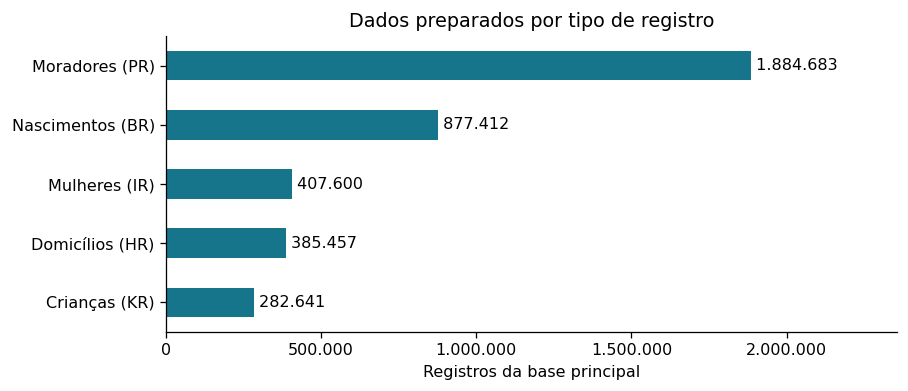

In [4]:
from pathlib import Path
from contextlib import closing
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

raiz = Path.cwd()
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 115})
azul = "#16758b"

def exibir(fig):
    fig.tight_layout()
    display(fig)
    plt.close(fig)

with closing(sqlite3.connect((raiz / "saude_mulher_dhs.db").as_uri() + "?mode=ro", uri=True)) as banco:
    tipos = {"Mulher": "Mulheres (IR)", "Nascimento": "Nascimentos (BR)",
             "Domicilio": "Domicílios (HR)", "Morador": "Moradores (PR)", "Crianca": "Crianças (KR)"}
    registros = pd.Series({nome: banco.execute(f"SELECT COUNT(*) FROM {tabela}").fetchone()[0]
                           for tabela, nome in tipos.items()})
    residencia = pd.read_sql_query("""
        SELECT v025 AS residencia, COUNT(*) AS entrevistas
        FROM Mulher GROUP BY v025
    """, banco)

fig, ax = plt.subplots(figsize=(8, 3.5))
registros.sort_values().plot.barh(ax=ax, color=azul)
ax.set(xlabel="Registros da base principal", title="Dados preparados por tipo de registro",
       xlim=(0, registros.max() * 1.25))
for y, valor in enumerate(registros.sort_values()):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)


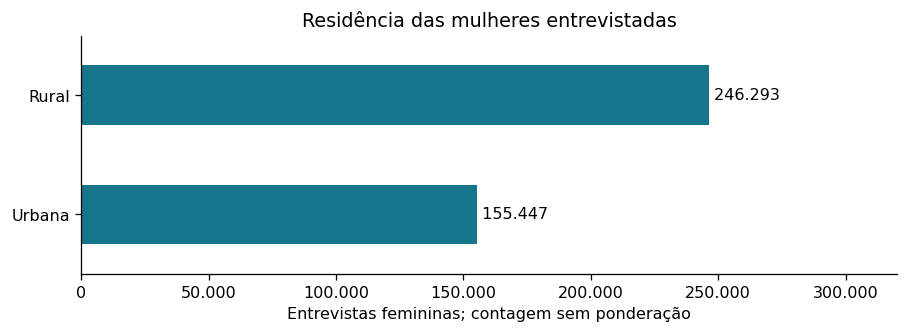

Residência sem informação válida: 5.860 entrevistas.


In [5]:
contagens = residencia.set_index("residencia").entrevistas.reindex([1, 2], fill_value=0)
contagens.index = ["Urbana", "Rural"]
sem_informacao = int(residencia.entrevistas.sum() - contagens.sum())
fig, ax = plt.subplots(figsize=(8, 3))
contagens.plot.barh(ax=ax, color=azul)
ax.set(xlabel="Entrevistas femininas; contagem sem ponderação",
       title="Residência das mulheres entrevistadas", xlim=(0, contagens.max() * 1.3))
for y, valor in enumerate(contagens):
    ax.text(valor, y, " " + f"{valor:,}".replace(",", "."), va="center")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
exibir(fig)
print(f"Residência sem informação válida: {sem_informacao:,} entrevistas.".replace(",", "."))


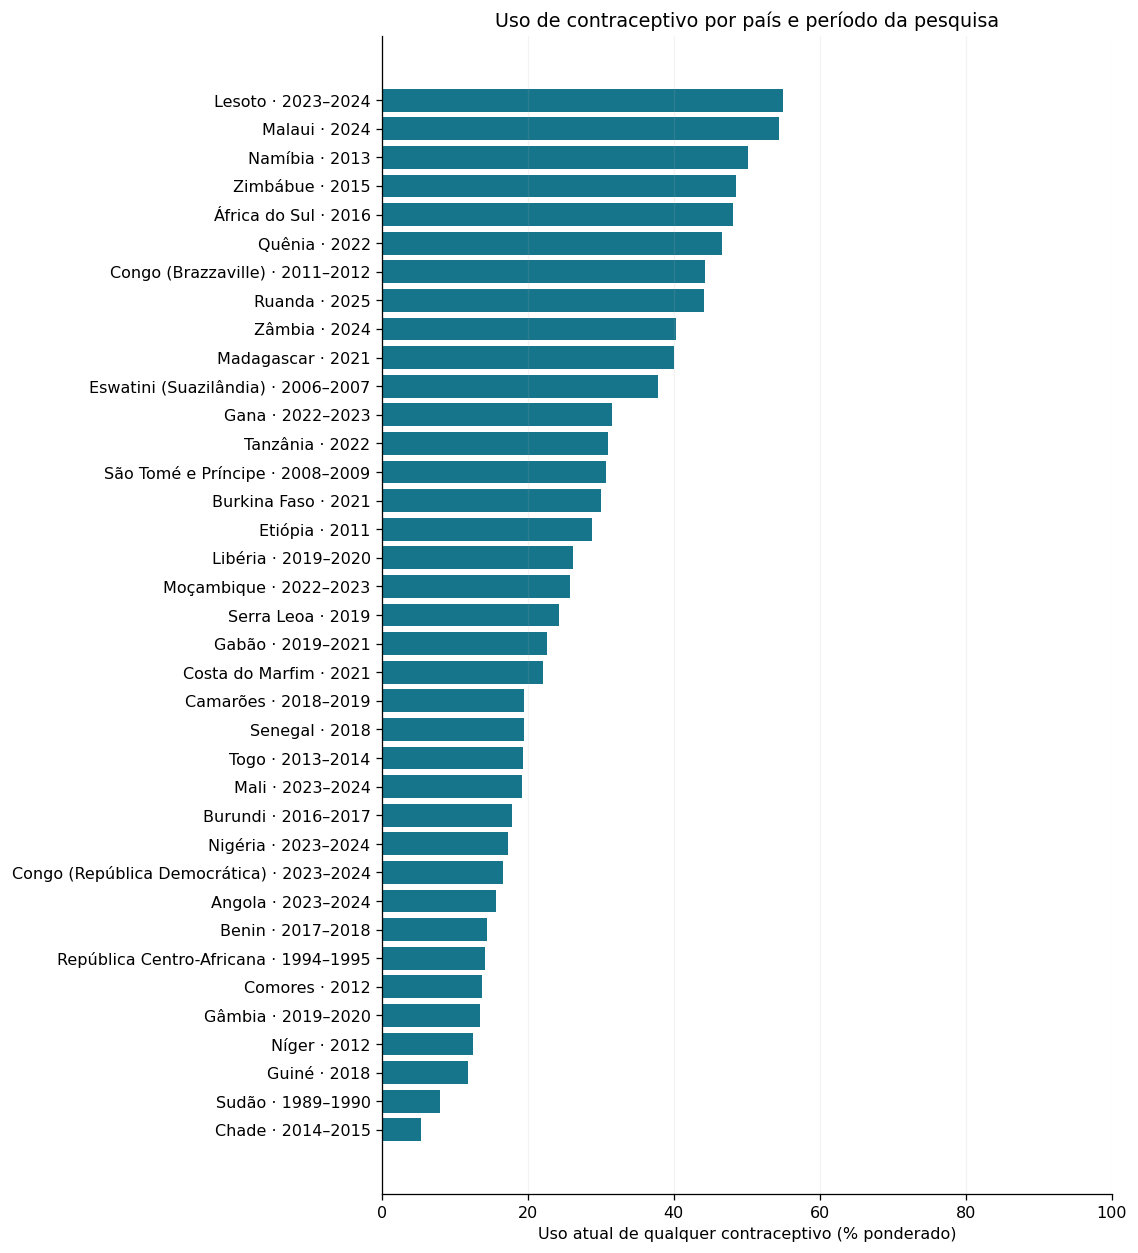

In [6]:
with closing(sqlite3.connect((raiz / "saude_mulher_normalizado.db").as_uri() + "?mode=ro", uri=True)) as banco:
    contracepcao = pd.read_sql_query("""
        SELECT p.codigo, p.nome, MIN(e.ano) AS inicio, MAX(e.ano) AS fim,
               ROUND(100.0 * SUM(e.peso * e.usa_metodo) / SUM(e.peso), 2) AS uso_percentual
        FROM Entrevista e
        JOIN Mulher m ON m.id = e.mulher_id
        JOIN Domicilio d ON d.id = m.domicilio_id
        JOIN Levantamento l ON l.id = d.levantamento_id
        JOIN Pais p ON p.codigo = l.pais_codigo
        WHERE e.coorte != 'nucleo_exclusivo' AND e.usa_metodo IS NOT NULL AND e.peso > 0
        GROUP BY p.codigo, p.nome
    """, banco).sort_values("uso_percentual")

periodos = contracepcao.apply(lambda r: str(int(r.inicio)) if r.inicio == r.fim
                              else f"{int(r.inicio)}–{int(r.fim)}", axis=1)
rotulos = contracepcao.nome + " · " + periodos
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(rotulos, contracepcao.uso_percentual, color=azul)
ax.set(xlim=(0, 100), xlabel="Uso atual de qualquer contraceptivo (% ponderado)",
       title="Uso de contraceptivo por país e período da pesquisa")
ax.grid(axis="x", alpha=.15)
exibir(fig)


### 3.2 Domínio e dados processados

Pesquisamos a **saúde da mulher na África Subsaariana**, com foco em contracepção, pré-natal e diferenças de residência, riqueza e escolaridade. A base principal contém **407.600 entrevistas femininas de 37 países**, dividas nesses arquivos contidos na pasta dados\relevantes:
- IR.csv.gz --> Idade, escolaridade, filhos e contracepção das mulheres 
- BR.csv.gz --> Histórico de nascidos vivos e pré-natal 
- HR.csv.gz e PR.csv.gz --> Moradia e composição dos domicílios 
- KR.csv.gz --> Saúde infantil vinculada à mãe 

A automação identificou os países e criou chaves para ligar mulher, domicílio e nascimento. O banco organiza esses dados em tabelas relacionadas, incluindo a ligação entre mulheres e métodos conhecidos.

### 3.3 Como os dados foram processados

A preparação foi realizada com preparar_dados_projeto.py e carregar_sqlite.py. O visualizador é iniciado por python database_python/server.py para rodar, acesse o [GitHub](https://github.com/limag-henrique/subsaharanAfrica-womenData)!

# 4. Diagrama ER

**9 entidades e 8 relacionamentos.** Uma mulher pode conhecer vários métodos, e cada método pode ser conhecido por várias mulheres (**M:N**). O vínculo registra o nível de conhecimento.

# 5. Diagrama relacional

`Conhecimento_Metodo` representa o M:N com chave composta

Pais (codigo, nome)

Levantamento (id, pais_codigo*, fase)
FK: pais_codigo $\rightarrow$ Pais(codigo)

Domicilio (id, levantamento_id*, cluster, numero, regiao, residencia, riqueza, eletricidade, fonte_agua, membros, origem)
FK: levantamento_id $\rightarrow$ Levantamento(id)

Morador (id, domicilio_id*, linha, sexo, idade, escolaridade_codigo, relacao_chefe_codigo)
FK: domicilio_id $\rightarrow$ Domicilio(id)

Mulher (id, domicilio_id*, linha, idade, escolaridade, filhos_nascidos_vivos, idade_primeiro_nascimento)
FK: domicilio_id $\rightarrow$ Domicilio(id)

Entrevista (mulher_id*, ano, mes, data_cmc, peso, usa_metodo, coorte)
FK: mulher_id $\rightarrow$ Mulher(id)

Nascimento (id, mulher_id*, indice, ano, mes, data_cmc, sexo, vivo, consultas_prenatal_codigo, local_parto_codigo, cesarea_codigo, assistencia_medico_codigo, assistencia_m3b_codigo, origem)
FK: mulher_id $\rightarrow$ Mulher(id)

Crianca (nascimento_id*, idade_anos, diarreia_codigo, cartao_vacina_codigo)
FK: nascimento_id $\rightarrow$ Nascimento(id)

Metodo (id, nome, classe)

Conhecimento_Metodo (mulher_id*, metodo_id*, nivel)
FK: mulher_id $\rightarrow$ Mulher(id)
FK: metodo_id $\rightarrow$ Metodo(id)

# 6. Consultas

## 6.1 Duas consultas envolvendo seleção e projeção

### 6.1.1 Consulta 1

### 6.1.2 Consulta 2

## 6.2 Três consultas envolvendo junção de duas relações

### 6.2.1 Consulta 3

### 6.2.2 Consulta 4

### 6.2.3 Consulta 5

## 6.3 Três consultas envolvendo junção de três ou mais relações

### 6.3.1 Consulta 6

### 6.3.2 Consulta 7

### 6.3.3 Consulta 8

## 6.4 Duas consultas envolvendo agregação sobre junção de duas ou mais relações

### 6.4.1 Consulta 9

### 6.4.2 Consulta 10

# 7. Autoavaliação dos membros

- **Henrique** - Sugestão de datasets; Solicitação de dados à agência americana; Plano de proposta da saúde da mulher africana; Importação dos 9GB de dados; Filtragem dos dados referentes às mulheres; Criação de repositório; Criação do Python Flask para análise visual dos dados; Tradução dos códigos para os respectivos nomes das entidades; Seções Descrição e Inovação Social da primeira proposta; Descrição e Manipulação de dados da segunda entrega; Diagrama Relacional da segunda entrega.

- **Felipe** - 

- **Izabela** - 

- **Alice** - 